In [2]:
RAW = '../data/raw'
PROCESSED = '../data/processed'

In [3]:
#Cần gom lại vì sẽ có những essay ở tập test trùng với tập train, phân chia tập test theo prompt riêng biệt so với train

import pandas as pd

splits = {'train': 'train.csv', 'test': 'test.csv'}
# df_train = pd.read_csv("hf://datasets/chillies/IELTS-writing-task-2-evaluation/" + splits["train"])
df_train = pd.read_csv(f'{RAW}/train.csv')
df_test = pd.read_csv(f'{RAW}/test.csv')
# df_test = pd.read_csv("hf://datasets/chillies/IELTS-writing-task-2-evaluation/" + splits["test"])
all_data = pd.concat([df_train, df_test])
all_data
# df_train.to_csv('../data/raw/train.csv')
# df_test.to_csv('../data/raw/test.csv')

,Unnamed: 0,prompt,essay,evaluation,band
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
...,...,...,...,...,...
486,486,"As well as making money, businesses also have ...",The role of companies is to produce all the go...,**Task Achievement:** 6\n\nThe essay effective...,6
487,487,"As well as making money, businesses also have ...",Although earning money is one of the most impo...,**Task Achievement:**\n\n- The essay adequatel...,7.5
488,488,"As well as making money, businesses also have ...",IIt is argued by many people that companies ha...,**Task Achievement: 4**\n\nThe essay addresses...,5
489,489,"As well as making money, businesses also have ...","In this modern era , everyone needs money for ...",## Task Achievement:\n- The candidate has adeq...,4


In [4]:
#Cấu trúc
print("CẤU TRÚC DF")
print(all_data.columns)

#Kiểm tra dữ liệu thiếu, dữ liệu trùng và kiểu dữ liệu
# 1. Kiểm tra dữ liệu thiếu
print("=== DỮ LIỆU THIẾU ===")
print("Train:")
print(all_data.isnull().sum())


# 2. Kiểm tra dòng trùng hoàn toàn
print("\n=== DÒNG TRÙNG HOÀN TOÀN ===")
print(all_data.duplicated().sum())

# 3. Kiểm tra bài luận trùng
print("\n=== BÀI LUẬN TRÙNG ===")
print(all_data['essay'].duplicated().sum())


# 4. Kiểm tra chuỗi rỗng hoặc chỉ chứa khoảng trắng
print("\n=== CHUỖI RỖNG ===")
for col in all_data.columns:
    print(
        col,
        "Train:",
        all_data[col].astype(str).str.strip().eq("").sum())
# len(train[train['essay'].duplicated()])

CẤU TRÚC DF
Index(['Unnamed: 0', 'prompt', 'essay', 'evaluation', 'band'], dtype='object')
=== DỮ LIỆU THIẾU ===
Train:
Unnamed: 0    0
prompt        0
essay         0
evaluation    0
band          0
dtype: int64

=== DÒNG TRÙNG HOÀN TOÀN ===
0

=== BÀI LUẬN TRÙNG ===
1339

=== CHUỖI RỖNG ===
Unnamed: 0 Train: 0
prompt Train: 0
essay Train: 0
evaluation Train: 0
band Train: 0


In [5]:
#Kiểm tra các bài luận trùng có bị gán nhiều mức điểm khác nhau không
duplicate_check = (
    all_data.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print("Số nhóm bài luận trùng:", len(duplicate_check))

print(
    "Số nhóm có nhiều mức điểm:",
    (duplicate_check["so_band_khac_nhau"] > 1).sum()
)
duplicate_check.sort_values(by='so_ban_ghi')

Số nhóm bài luận trùng: 1217
Số nhóm có nhiều mức điểm: 477


,essay,so_ban_ghi,so_band_khac_nhau
1216,various circumstances exist that would encoura...,2,1
33,According to some people vital aim of schools ...,2,1
34,"According to some people, watching TV programs...",2,1
35,"According to some, the technological revolutio...",2,1
36,According to the enthusiasm of the generations...,2,2
...,...,...,...
481,It is inevitable for prominent people to have ...,4,2
482,It is inevitable for prominent people to have ...,4,2
931,The advertising industry has undeniably thrive...,4,2
1079,There is an opinion that employers should not ...,5,4


In [6]:
#Xem một ví dụ cụ thể
# Lấy bài luận trùng đầu tiên có nhiều mức điểm
conflicting_essays = duplicate_check[
    duplicate_check["so_band_khac_nhau"] > 1
]["essay"]

sample_essay = conflicting_essays.iloc[0]

# Hiển thị các bản ghi tương ứng
display(
    all_data.loc[
        all_data["essay"] == sample_essay,
        ["prompt", "essay", "band", "evaluation"]
    ]
)

,prompt,essay,band,evaluation
3484,Most of the urgent problems can only be solved...,\nIt is true that some people believe that cro...,6\r\r\r\r,**Task Achievement:** \n\n- **Strengths:** \n ...
5800,Most of the urgent problems can only be solved...,\nIt is true that some people believe that cro...,6\r\r\r,### Task Achievement:\nThe candidate has adequ...


In [7]:
#Chuẩn hóa band để so sánh chính xác
# Tạo cột điểm dạng số để kiểm tra, không sửa dữ liệu gốc
all_data_check = all_data.copy()

all_data_check["band_num"] = pd.to_numeric(
    all_data_check["band"].astype(str).str.strip(),
    errors="coerce"
)

duplicate_check_num = (
    all_data_check.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band_num", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print(
    "Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa:",
    (duplicate_check_num["so_band_khac_nhau"] > 1).sum()
)

print(
    "Số giá trị band không chuyển được sang số:",
    all_data_check["band_num"].isna().sum()
)
all_data_check[all_data_check['band_num'].isna()]

Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa: 4
Số giá trị band không chuyển được sang số: 612


,Unnamed: 0,prompt,essay,evaluation,band,band_num
8,8,Interviews form the basic selection criteria f...,"Sometimes, people argue that interview is not ...",**Task Achievement:** <4\n- The essay somewhat...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,NaN
9,9,Interviews form the basic selecting criteria f...,"overall,interviews form the basic crteria ffor...",## Task Achievement:\n- The candidate has not ...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,NaN
20,20,Interviews form the basic selection criteria f...,"For a very long time, interviews are the most ...",## Task Achievement:\n- The candidate has adeq...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,NaN
28,28,Interviews form the basic selecting criteria f...,The meeting is the principal for selecting the...,**Task Achievement:**\n\n- The candidate has n...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,NaN
32,32,interviews from the basic selection criteria f...,"it is argued that in big organisations, a ques...",**Task Achievement:**\n\n- The candidate has n...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,NaN
...,...,...,...,...,...,...
457,457,There are several factors that motivate people...,various circumstances exist that would encoura...,**Task Achievement: 2**\n\nThe essay fails to ...,<4\r,NaN
471,471,More and more people these days work harder an...,"In today's fast-pace life, getting along with ...",**Task Achievement:** \nThe essay inadequately...,<4\r,NaN
472,472,"In many countries today, parents are able to c...","In some counties, parents teach their kids in ...",**Task Achievement:**\n\nThe essay addresses t...,<4\r,NaN
478,478,Studies have shown that many criminals have a ...,Most of the criminals are uneducated so some p...,**Task Achievement: 2**\n\n- The essay address...,<4,NaN


In [8]:
#Kiểm tra toàn bộ các dạng nhãn band
# Chuẩn hóa ký tự xuống dòng và khoảng trắng
band_cleaned = (
    all_data["band"]
    .astype(str)
    .str.replace(r"[\r\n\t]", "", regex=True)
    .str.strip()
)

print("Các nhãn band sau khi loại ký tự thừa:")
display(band_cleaned.value_counts().to_frame("Số lượng"))

print("\nSố nhãn bắt đầu bằng '<':",
      band_cleaned.str.startswith("<").sum())

print("\nSố nhãn còn lại không phải số:",
      pd.to_numeric(band_cleaned, errors="coerce").isna().sum())

Các nhãn band sau khi loại ký tự thừa:


,Số lượng
band,
7,1434
6.5,1235
6,1201
7.5,1146
5,1083
5.5,1013
8,735
4.5,676
4,627



Số nhãn bắt đầu bằng '<': 612

Số nhãn còn lại không phải số: 612


In [9]:
#Chuẩn hóa nhãn band cho cả all và test
import pandas as pd

def clean_band(series):
    return (
        series.astype(str)
        .str.replace(r"[\r\n\t]", "", regex=True)
        .str.strip()
    )

all_data["band_clean"] = clean_band(all_data["band"])
# test["band_clean"] = clean_band(test["band"])

print("Phân bố nhãn band trong all_data:")
display(all_data["band_clean"].value_counts().sort_index().to_frame("Số lượng"))
# print("\nPhân bố nhãn band trong test:")
# display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

Phân bố nhãn band trong all_data:


,Số lượng
band_clean,
4,627
4.5,676
5,1083
5.0,1
5.5,1013
6,1201
6.5,1235
7,1434
7.5,1146


In [10]:
#Chuẩn hóa định dạng nhãn điểm
def normalize_band(series):
    cleaned = clean_band(series)

    def normalize_one(value):
        if value == "<4":
            return "<4"

        try:
            number = float(value)
            return str(int(number)) if number.is_integer() else str(number)
        except ValueError:
            return value

    return cleaned.apply(normalize_one)


all_data["band_clean"] = normalize_band(all_data["band"])
# test["band_clean"] = normalize_band(test["band"])

print("Phân bố nhãn all_data sau chuẩn hóa:")
display(all_data["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

# print("\nPhân bố nhãn test sau chuẩn hóa:")
# display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nTổng số mẫu all_data:", len(all_data))
# print("Tổng số mẫu test:", len(test))

Phân bố nhãn all_data sau chuẩn hóa:


,Số lượng
band_clean,
4,627
4.5,676
5,1084
5.5,1013
6,1201
6.5,1235
7,1434
7.5,1146
8,735



Tổng số mẫu all_data: 10324


Bảng phân bố điểm:


,Số lượng
band_clean,
<4,612
4,627
4.5,676
5,1084
5.5,1013
6,1201
6.5,1235
7,1434
7.5,1146


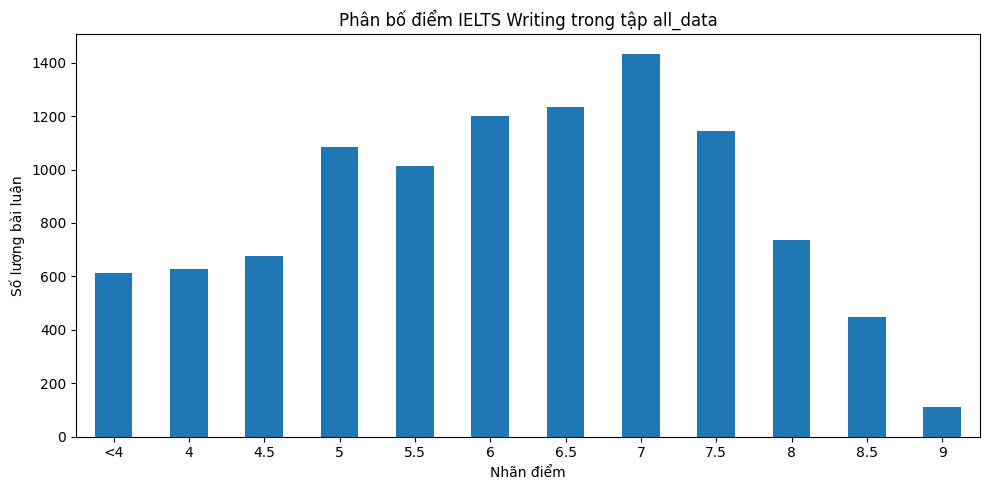

In [15]:
#Khám phá phân bố điểm trong tập train
import matplotlib.pyplot as plt

band_counts = all_data["band_clean"].value_counts()

# Sắp xếp nhãn theo thứ tự điểm
band_order = ["<4", "4", "4.5", "5", "5.5",
              "6", "6.5", "7", "7.5", "8", "8.5", "9"]

band_counts = band_counts.reindex(band_order, fill_value=0)

print("Bảng phân bố điểm:")
display(band_counts.to_frame("Số lượng"))

plt.figure(figsize=(10, 5))
band_counts.plot(kind="bar")
plt.title("Phân bố điểm IELTS Writing trong tập all_data")
plt.xlabel("Nhãn điểm")
plt.ylabel("Số lượng bài luận")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
#CHỘ NÀY DÙNG ĐỂ CHIA DATA

In [14]:
#Khám phá độ dài bài luận
# Tạo bản sao để phân tích, không sửa dữ liệu gốc
all_data_eda = all_data.copy()

# Đếm số từ trong mỗi bài luận
all_data_eda["word_count"] = (
    all_data_eda["essay"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Thống kê độ dài bài luận (số từ):")
display(all_data_eda["word_count"].describe().to_frame().T)

print("\n5 bài luận ngắn nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count")
    .head(5)
)

print("\n5 bài luận dài nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count", ascending=False)
    .head(5)
)
# print(all_data['essay'])

Thống kê độ dài bài luận (số từ):


,count,mean,std,min,25%,50%,75%,max
word_count,10324.0,292.448566,57.817552,1.0,263.0,289.0,321.0,1557.0



5 bài luận ngắn nhất:


,essay,word_count,band_clean
1579,#NAME?,1,4
5129,"Nowadays,advertising is going to be more and m...",50,<4
1047,"Nowdays, abundant of old age people are experi...",50,<4
8600,"In this twenty-first century, I suggest that t...",51,<4
4402,"In this twenty-first century, I suggest that t...",51,<4



5 bài luận dài nhất:


,essay,word_count,band_clean
1610,The automotive industry is undergoing one of ...,1557,4.5
2846,Global warming is not a prediction. It is happ...,792,4
1716,"In this contemporary era, every citizen of a c...",678,6
5924,Nobody can deny the growing economic progress ...,591,5
4475,"In this day and age, young people have been st...",578,6.5
